# P7.15 — Filtro em escada com janela de Kaiser vs. Parks-McClellan (Exemplo 7.26)

**Referência:** Ingle & Proakis, *DSP Using MATLAB*, 3ª ed., p. 380 (exercício) e pp. 367–368 (Exemplo 7.26) · DTA §2.1 (item 7) e §4 (Resolução P7.15).

> *Design the staircase filter of Example 7.26 using the Kaiser window approach. The specifications are: Band-1: 0 ≤ ω ≤ 0.3π, Ideal gain = 1, δ1 = 0.01; Band-2: 0.4π ≤ ω ≤ 0.7π, Ideal gain = 0.5, δ2 = 0.005; Band-3: 0.8π ≤ ω ≤ π, Ideal gain = 0, δ3 = 0.001. Compare the filter length of this design with that of Example 7.26. Provide a plot of the magnitude response in dB. Do not use the fir1 function.*

| Banda | Faixa | Ganho ideal | Tolerância |
|---|---|---|---|
| 1 | $0 \le \omega \le 0.3\pi$ | 1 | $\delta_1 = 0.01$ |
| 2 | $0.4\pi \le \omega \le 0.7\pi$ | 0.5 | $\delta_2 = 0.005$ |
| 3 | $0.8\pi \le \omega \le \pi$ | 0 | $\delta_3 = 0.001$ |

In [1]:
# Configuração do ambiente (local ou Google Colab)
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # No Colab, disponibilize o projeto em PROJECT_DIR antes de executar:
    #   (a) Arquivos → upload de dsp-avaliacao-2.zip e  !unzip -q dsp-avaliacao-2.zip
    #   (b) ou monte o Drive:  from google.colab import drive; drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/dsp-avaliacao-2")
    %pip install -q -r {PROJECT_DIR}/requirements.txt
else:
    PROJECT_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())

for p in (PROJECT_DIR, PROJECT_DIR / "src"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
print("Projeto em:", PROJECT_DIR)

Projeto em: /mnt/storage/projects/dsp-avaliacao-2


## 1. Método de Kaiser

**Tolerância de projeto:** $\delta = \min(\delta_1, \delta_2, \delta_3) = 0.001 \Rightarrow A_s = 60$ dB, e com $A_s \ge 50$: $\beta = 0.1102(A_s - 8.7) = 5.6533$.

**Estimativa:** com $\Delta\omega = 0.1\pi$ nas duas transições, $M \approx \lceil 52.05/(2.285 \cdot 0.1\pi) \rceil + 1 = 74$.

**Paridade.** O ganho em $\omega = \pi$ é zero (banda 3), então o Tipo 2 é admissível. O DTA força $M = 75$ sem necessidade.

**Resposta ideal em degraus.** Com cortes no meio das transições, $\omega_{c1} = 0.35\pi$ e $\omega_{c2} = 0.75\pi$:

$$h_d(n) = G_1 h_{LP,1}(n) + G_2[h_{LP,2}(n) - h_{LP,1}(n)] = 0.5\,h_{LP}(n; 0.35\pi) + 0.5\,h_{LP}(n; 0.75\pi)$$

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from dsp_av2.fir import analysis
from dsp_av2.specs import EXAMPLE_7_26_M, P7_15 as SPEC
from dsp_av2.validation import validate_fir_tolerance
from exercises import p7_15

e = p7_15.estimate()
print(f"A_s = {e.params['As_design_dB']:.2f} dB,  β = {e.params['beta']:.5f},  "
      f"ωc = {e.cutoffs[0]:g}π e {e.cutoffs[1]:g}π,  estimativa M = {e.M}")

A_s = 60.00 dB,  β = 5.65326,  ωc = 0.35π e 0.75π,  estimativa M = 74


## 2. Busca do comprimento mínimo (β fixo)

In [3]:
s = p7_15.search()
print("Últimos comprimentos testados (M, atende?):", s.tried[-5:])
d = s.best
print(f"\nComprimento mínimo verificado: M = {d.M} (Tipo {analysis.linear_phase_type(d.h)})\n")
print(validate_fir_tolerance(d, n_points=200001))

Últimos comprimentos testados (M, atende?): ((68, False), (69, False), (70, False), (71, False), (72, True))

Comprimento mínimo verificado: M = 72 (Tipo 2)

Validação P7.15 (Tipo 2 de fase linear)
  [OK  ] ||H| − 1| em [0π, 0.3π]: 0.0010 <= 0.0100  (folga +0.0090)
  [OK  ] ||H| − 0.5| em [0.4π, 0.7π]: 0.0009 <= 0.0050  (folga +0.0041)
  [OK  ] ||H| − 0| em [0.8π, 1π]: 0.0009 <= 0.0010  (folga +0.0001)
  Resultado: ATENDE à especificação


## 3. Resultados

Pedido: magnitude em dB (último painel). $h(n)$ e $H_r(\omega)$ entram como contexto. Em $H_r$ os três degraus e suas tolerâncias aparecem com clareza. Em dB, o degrau de ganho 0.5 aparece em $20\log_{10}0.5 \approx -6$ dB.

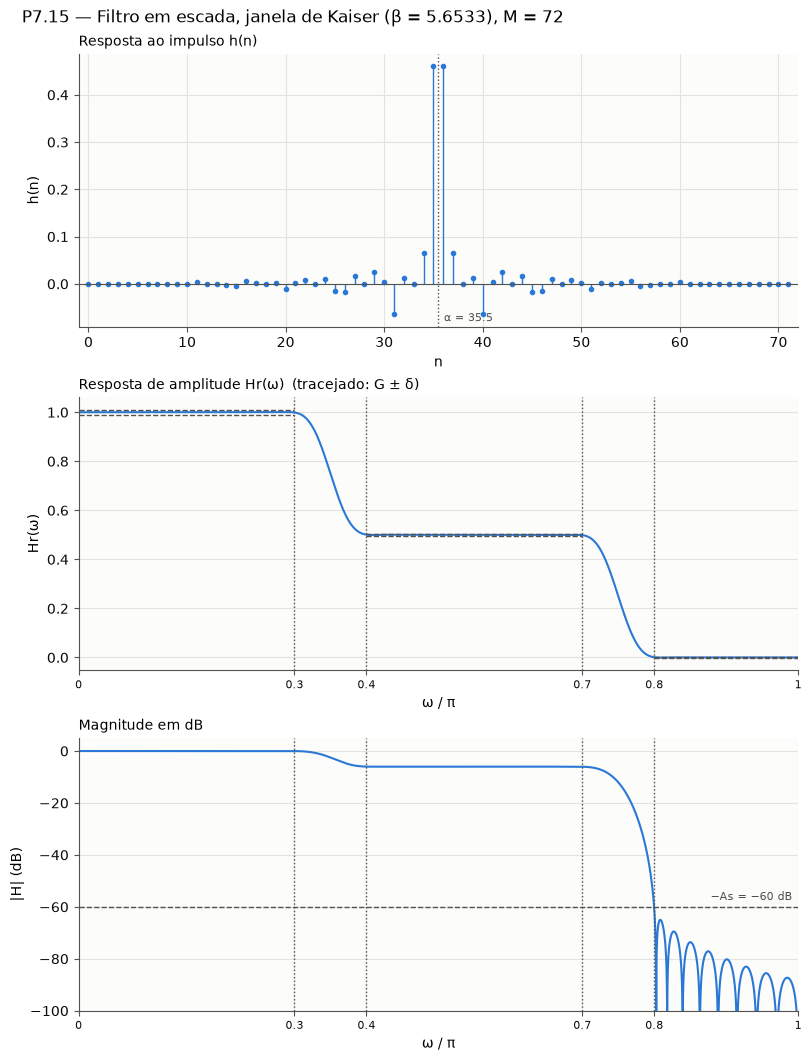

In [4]:
fig = p7_15.plot(d)
plt.show()

## 4. Comparação com o Exemplo 7.26 (Parks-McClellan)

O Exemplo 7.26 resolve o mesmo filtro com o algoritmo equiripple (`firpm`) e chega a **M = 49**. Pelos valores informados das pp. 367–368: M = 51 → 62.07 dB, M = 50 → 60.03 dB, M = 49 → 60.61 dB.

Para não depender só do valor citado, o projeto equiripple foi **reproduzido** com `scipy.signal.remez` (o equivalente ao `firpm`), com pesos $W_k = \delta_{\min}/\delta_k = [0.1,\ 0.2,\ 1]$, que igualam os erros ponderados:

In [5]:
r = p7_15.remez_search()
print(" M   atende?   A_s banda 3 [dB]")
for M, ok, a in r.tried[-6:]:
    print(f"{M:3d}    {'sim' if ok else 'não'}        {a:6.2f}")
print(f"\nEquiripple (remez): M mínimo = {r.M_min}   |   Livro (Exemplo 7.26): M = {EXAMPLE_7_26_M}")
print(f"Kaiser / Parks-McClellan = {d.M} / {EXAMPLE_7_26_M} = {d.M / EXAMPLE_7_26_M:.3f}  "
      f"(Kaiser {100 * (d.M / EXAMPLE_7_26_M - 1):.0f}% mais longo)")

 M   atende?   A_s banda 3 [dB]
 44    não         57.08
 45    não         56.79
 46    não         58.93
 47    não         58.05
 48    não         59.06
 49    sim         60.48

Equiripple (remez): M mínimo = 49   |   Livro (Exemplo 7.26): M = 49
Kaiser / Parks-McClellan = 72 / 49 = 1.469  (Kaiser 47% mais longo)


A reprodução confere com o livro: $M = 49$, com atenuações a ~0.1 dB das citadas (a diferença vem da grade de medição). Em $M = 50$, nossa medição dá 59.94 dB (< 60) e o livro dá 60.03 dB, mas isso não altera o mínimo.

### 4.1 Por que a janela perde tanto?

- **O método da janela não distingue as faixas.** As ondulações saem praticamente iguais em todas as bandas (≈ 0.001 acima), embora a banda 1 tolere 10 vezes mais ($\delta_1 = 0.01$). O comprimento é ditado pela banda mais exigente, e a folga das outras é desperdiçada.
- **O Parks-McClellan pondera o erro por banda** ($W_k$) e distribui a ondulação de forma ótima (equiripple). Ele usa toda a tolerância disponível em cada banda.

### 4.2 E se o $A_s$ de Kaiser fosse ajustado? (decisão D7)

O DTA projeta com $A_s = 60$ dB, mas os degraus têm altura 0.5, e a ondulação do método da janela escala com a altura do salto. Isso sugere que 60 dB é conservador. Testando outros valores de $A_s$, cada um com seu $\beta$ e seu comprimento mínimo:

In [6]:
from dsp_av2.fir import ideal, windows as W
wg = analysis.frequency_grid(SPEC.edges, analysis.DENSE_GRID_POINTS)
print(" A_s [dB]    β       M mínimo")
for As in (60, 57, 54, 51):
    beta = W.kaiser_beta(As)
    for M in range(40, 100):
        h = ideal.ideal_multiband([0.35 * np.pi, 0.75 * np.pi], [1, 0.5, 0], M) * W.kaiser(M, beta)
        if all(dv <= b.delta for dv, b in zip(analysis.band_deviations(h, SPEC.bands, wg), SPEC.bands)):
            print(f"  {As:4.0f}     {beta:.4f}     {M}")
            break

 A_s [dB]    β       M mínimo
    60     5.6533     72
    57     5.3227     69
    54     4.9921     68


    51     4.6615     71


Ajustando $\beta$, o melhor resultado de Kaiser fica em torno de $M = 68$, ainda **~40% acima** do equiripple. A diferença é estrutural (item 4.1) e não pode ser eliminada só com a escolha do parâmetro da janela. O projeto oficial segue o critério do livro ($A_s = 60$ dB, $M = 72$).

## 5. Conclusão

- Kaiser: $A_s = 60$ dB, $\beta = 5.6533$, estimativa $M = 74$. O comprimento mínimo verificado é **$M = 72$** (Tipo 2, admissível porque o ganho em $\pi$ é 0). O DTA dá 75 por forçar M ímpar.
- Exemplo 7.26 (Parks-McClellan): **$M = 49$**, confirmado de forma independente com `scipy.signal.remez`.
- A janela de Kaiser exige um filtro **≈ 47% mais longo** (72/49). Com o $M = 75$ do DTA, a diferença seria de 53%, e não os "~35%" que o DTA afirma ($1 - 49/75 = 35\%$ é a redução vista a partir do Kaiser, não o acréscimo).
- A causa é estrutural: a janela iguala as ondulações de todas as bandas, enquanto o equiripple pondera cada banda pela sua tolerância.